## **EDA for Time Series**

In a time series **the order of the rows is the information**: the same values shuffled would tell a different story. The EDA therefore adds new questions to the usual ones: *what is the frequency, are there gaps, is there a trend, is there seasonality, is the series stationary, how much autocorrelation is there and what is anomalous?*

| Section | Dataset | Content |
|---|---|---|
| 01 | Airline Passengers ( monthly, 1949 - 1960 ) | Structure, trend, seasonality, decomposition, stationarity, autocorrelation, anomalies, baselines and forecasts |
| 02 | Random sample ( 50 daily observations ) | Trend, seasonality and noise created on purpose |

**Notebooks of this series:** 1. Manual Data Profiling · 2. Automatic Data Profiling · 3. Checking Issues in Dataframes · 4. Graphics & Illustrations · 5. EDA for Time Series

### **00. Import Libs**

In [3]:
#Import Specific Libs
from scipy import stats
from google.colab import files;
from collections import Counter;
from IPython.display import IFrame, display, HTML;

In [4]:
#Import the Others Libs
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import plotly.express as px
import seaborn as sns
import pandas as pd
import numpy as np
import re

In [5]:
#Import Statistical and Time Series Libs
import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.graphics.mosaicplot import mosaic
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [6]:
#Ignore Error Message
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
#Import Additional Time Series Libs
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.model_selection import TimeSeriesSplit

### **01. Time Series Analysis**

In [59]:
#Load the Time Series Dataset ( Airline Passengers )
flights = sns.load_dataset('flights')
flights.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [60]:
#Create the Datetime Index ( Monthly Frequency )
flights['date'] = pd.to_datetime(flights['year'].astype(str) + '-' + flights['month'].astype(str).str[:3], format='%Y-%b')
ts = flights.set_index('date')['passengers'].sort_index().asfreq('MS')
ts.head()

,passengers
date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [61]:
#Time Series Structure ( Range, Frequency, Gaps and Duplicates )
print('Start:', ts.index.min().date(), '| End:', ts.index.max().date())
print('Observations:', len(ts))
print('Inferred frequency:', pd.infer_freq(ts.index))
print('Missing timestamps / values:', ts.isnull().sum())
print('Duplicated timestamps:', ts.index.duplicated().sum())
# If gaps exist: ts.interpolate(method='time') fills them using the neighbors in time

Start: 1949-01-01 | End: 1960-12-01
Observations: 144
Inferred frequency: MS
Missing timestamps / values: 0
Duplicated timestamps: 0


In [ ]:
#Descriptive Statistics of the Series
ts.describe().round(2)

In [ ]:
#Test the Imputation of Gaps ( Hide Known Values and Measure the Error )
# The series has no gaps, so we create them: hide 12 known values, fill them with each method and compare with the truth
rng = np.random.default_rng(42)
hidden = rng.choice(np.arange(12, len(ts) - 1), size=12, replace=False)
ts_gaps = ts.astype(float)
ts_gaps.iloc[hidden] = np.nan

filled = {
    'Linear interpolation': ts_gaps.interpolate(method='time'),
    'Forward fill': ts_gaps.ffill(),
    'Same month last year': ts_gaps.fillna(ts_gaps.shift(12)).fillna(ts_gaps.interpolate(method='time')),
    'Rolling mean ( 5 months )': ts_gaps.fillna(ts_gaps.rolling(5, center=True, min_periods=1).mean())
}

truth = ts.iloc[hidden]
imputation = {}
for name, series in filled.items():
    error = series.iloc[hidden] - truth
    imputation[name] = {'MAE': error.abs().mean(), 'RMSE': np.sqrt((error ** 2).mean()), 'MAPE_%': (error.abs() / truth).mean() * 100}
pd.DataFrame(imputation).T.round(2).sort_values('RMSE')

In [62]:
#Create Calendar Features
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ts_df = ts.to_frame()
ts_df['year'] = ts_df.index.year
ts_df['quarter'] = ts_df.index.quarter
ts_df['month'] = ts_df.index.month
ts_df['month_name'] = ts_df['month'].map(lambda m: month_labels[m - 1])
ts_df.head()

,passengers,year,quarter,month,month_name
date,,,,,
1949-01-01,112,1949,1,1,Jan
1949-02-01,118,1949,1,2,Feb
1949-03-01,132,1949,1,3,Mar
1949-04-01,129,1949,2,4,Apr
1949-05-01,121,1949,2,5,May


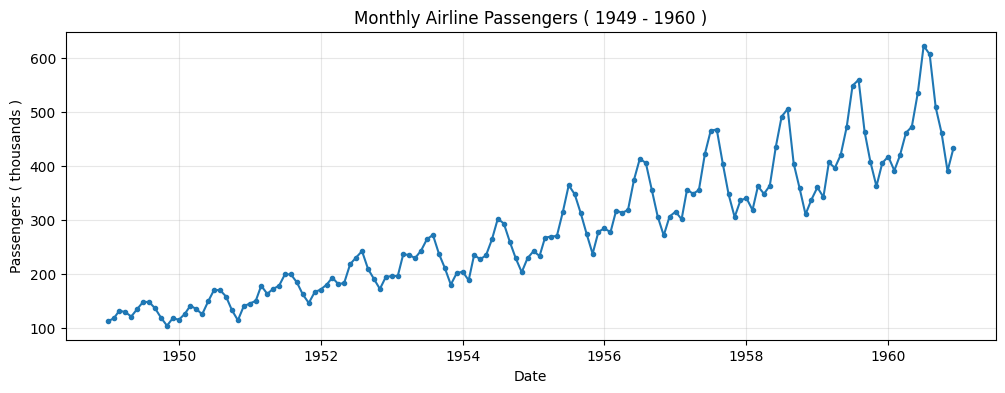

In [63]:
#Example 28 ( Line Plot of the Series )
plt.figure(figsize=(12, 4))
plt.plot(ts, marker='o', markersize=3)
plt.title('Monthly Airline Passengers ( 1949 - 1960 )')
plt.xlabel('Date')
plt.ylabel('Passengers ( thousands )')
plt.grid(alpha=0.3)
plt.show()

In [64]:
#Example 29 ( Interactive Line Plot with Range Slider )
fig = px.line(ts_df.reset_index(), x='date', y='passengers', title='Monthly Airline Passengers')
fig.update_xaxes(rangeslider_visible=True)
fig.show()

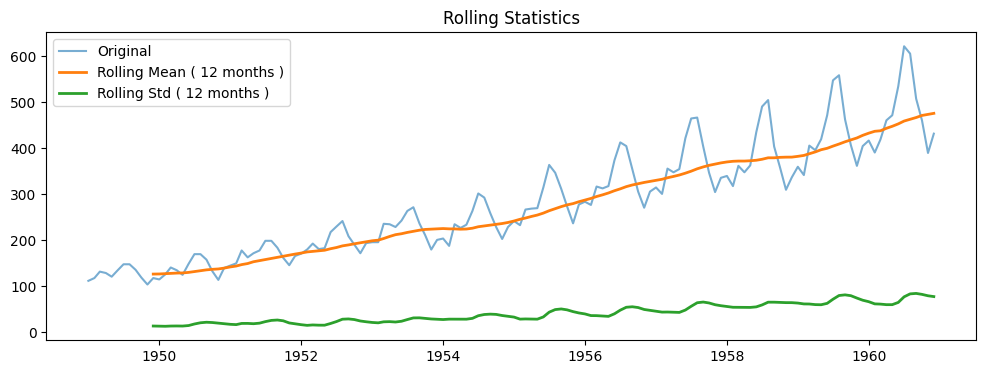

In [65]:
#Example 30 ( Rolling Mean and Rolling Standard Deviation )
roll_mean = ts.rolling(window=12).mean()
roll_std = ts.rolling(window=12).std()

plt.figure(figsize=(12, 4))
plt.plot(ts, label='Original', alpha=0.6)
plt.plot(roll_mean, label='Rolling Mean ( 12 months )', linewidth=2)
plt.plot(roll_std, label='Rolling Std ( 12 months )', linewidth=2)
plt.title('Rolling Statistics')
plt.legend()
plt.show()

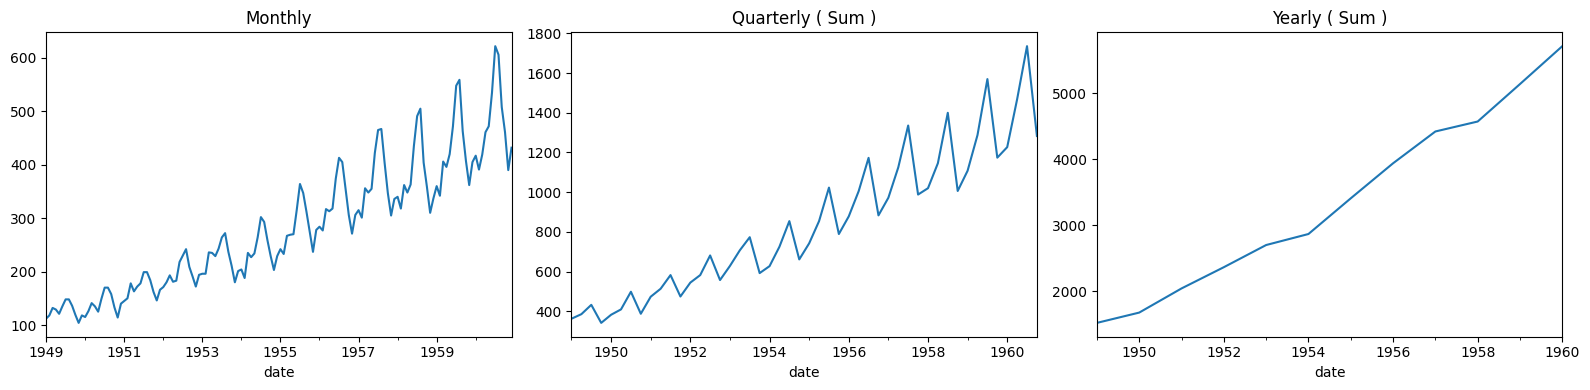

In [66]:
#Example 31 - Resampling ( Monthly, Quarterly and Yearly )
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ts.plot(ax=axes[0], title='Monthly')
ts.resample('QS').sum().plot(ax=axes[1], title='Quarterly ( Sum )')
ts.resample('YS').sum().plot(ax=axes[2], title='Yearly ( Sum )')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 01 ( Year-over-Year Growth and CAGR )
# pct_change( 12 ) compares each month with the same month of the previous year, so the seasonality does not distort the comparison
yoy = ts.pct_change(12) * 100
n_years = len(ts) // 12
cagr = (ts.iloc[-12:].sum() / ts.iloc[:12].sum()) ** (1 / (n_years - 1)) - 1

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(yoy)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Year-over-Year Growth ( % )')
ax.set_ylabel('%')
plt.tight_layout()
plt.show()
print(f'Compound annual growth rate ( first year vs last year ): {cagr * 100:.2f}% per year')

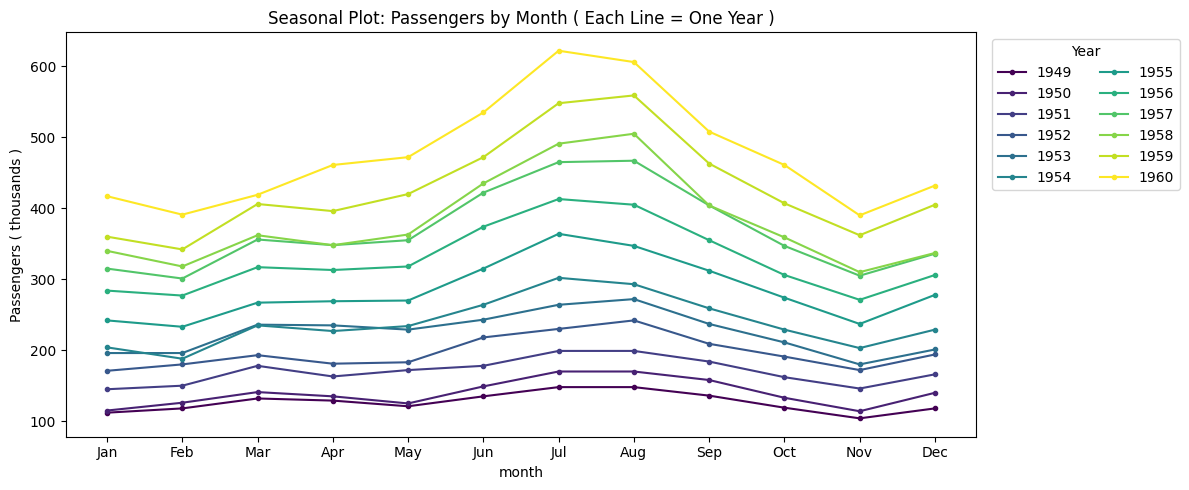

In [67]:
#Example 32 - Seasonality ( One Line per Year )
seasonal_pivot = ts_df.pivot_table(index='month', columns='year', values='passengers')
ax = seasonal_pivot.plot(figsize=(12, 5), colormap='viridis', marker='o', markersize=3)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)
ax.set_title('Seasonal Plot: Passengers by Month ( Each Line = One Year )')
ax.set_ylabel('Passengers ( thousands )')
ax.legend(title='Year', ncol=2, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

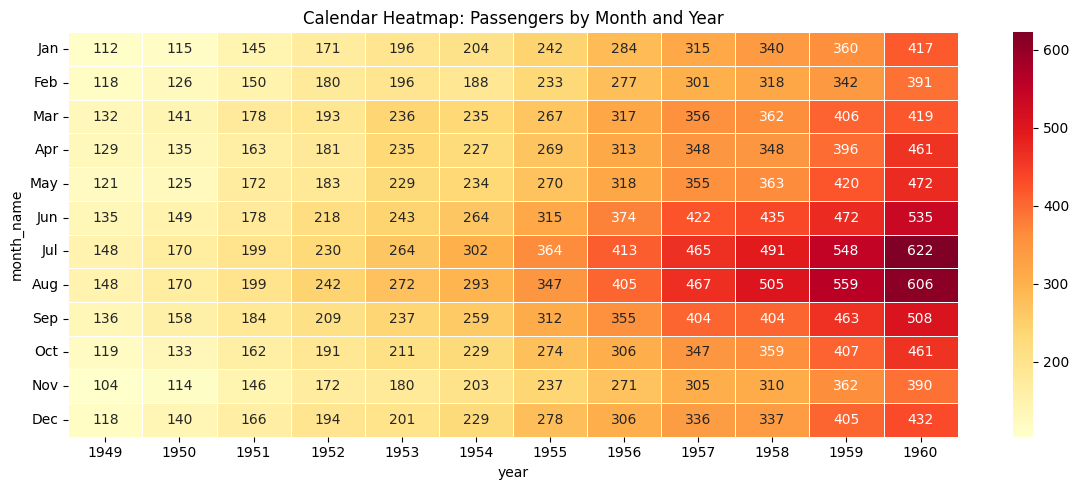

In [68]:
#Example 33 - Calendar Heatmap ( Month x Year )
calendar_pivot = ts_df.pivot_table(index='month_name', columns='year', values='passengers').reindex(month_labels)
plt.figure(figsize=(12, 5))
sns.heatmap(calendar_pivot, cmap='YlOrRd', annot=True, fmt='.0f', linewidths=0.5)
plt.yticks(rotation=0)
plt.title('Calendar Heatmap: Passengers by Month and Year')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 02 ( Distribution by Month and by Year )
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.boxplot(data=ts_df, x='month_name', y='passengers', order=month_labels, ax=axes[0])
axes[0].set_title('Passengers by Month ( Seasonality )')
sns.boxplot(data=ts_df, x='year', y='passengers', ax=axes[1])
axes[1].set_title('Passengers by Year ( Trend )')
plt.tight_layout()
plt.show()

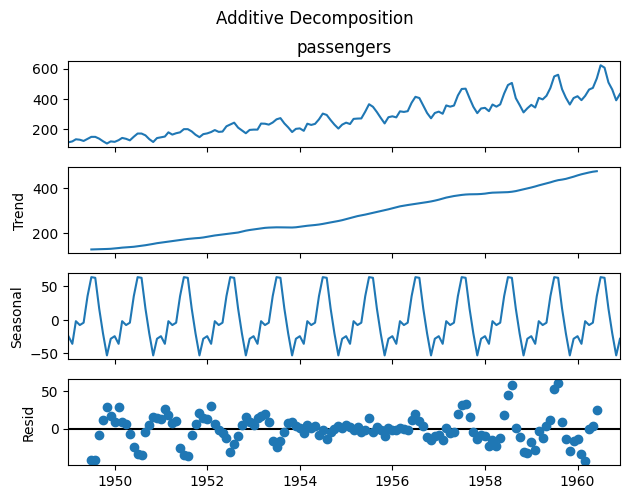

In [69]:
#Example 34 - Classical Decomposition ( Additive: Series = Trend + Seasonal + Residual )
dec_add = seasonal_decompose(ts, model='additive', period=12)
dec_add.plot()
plt.suptitle('Additive Decomposition', y=1.03)
plt.show()

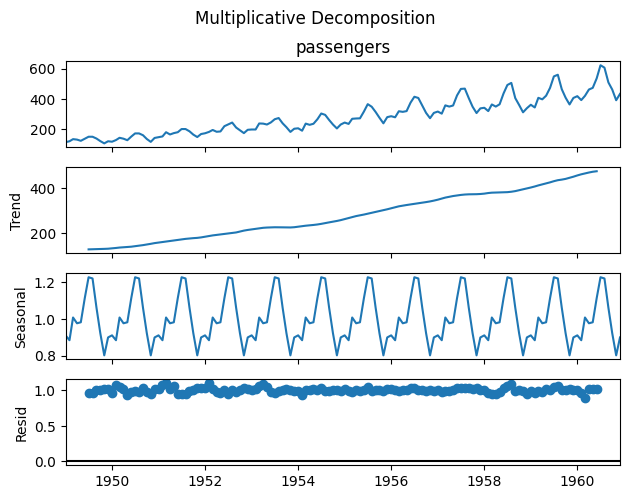

In [70]:
#Example 35 - Classical Decomposition ( Multiplicative: Series = Trend x Seasonal x Residual )
dec_mul = seasonal_decompose(ts, model='multiplicative', period=12)
dec_mul.plot()
plt.suptitle('Multiplicative Decomposition', y=1.03)
plt.show()

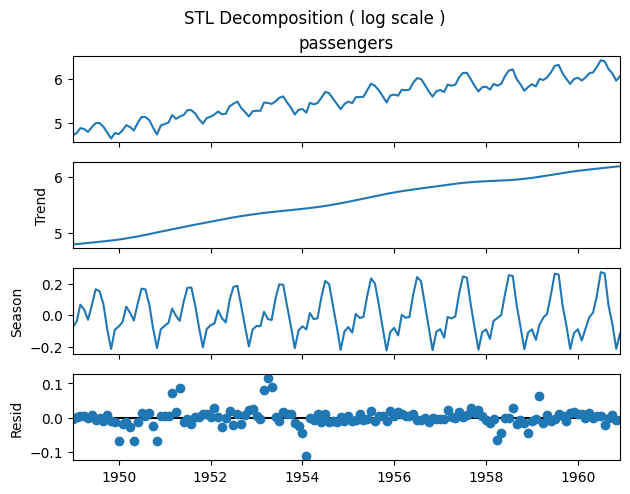

In [71]:
#Example 36 - STL Decomposition ( Robust to Outliers, Applied to the Log of the Series )
stl = STL(np.log(ts), period=12, robust=True).fit()
stl.plot()
plt.suptitle('STL Decomposition ( log scale )', y=1.02)
plt.show()

In [ ]:
#Extra 03 ( Strength of the Trend and of the Seasonality )
# Strength = 1 - Var( residual ) / Var( component + residual ) | 0 = no structure | 1 = the component explains almost all the variation
trend_strength = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
seasonal_strength = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f'Trend strength:       {trend_strength:.3f}')
print(f'Seasonal strength:    {seasonal_strength:.3f}')

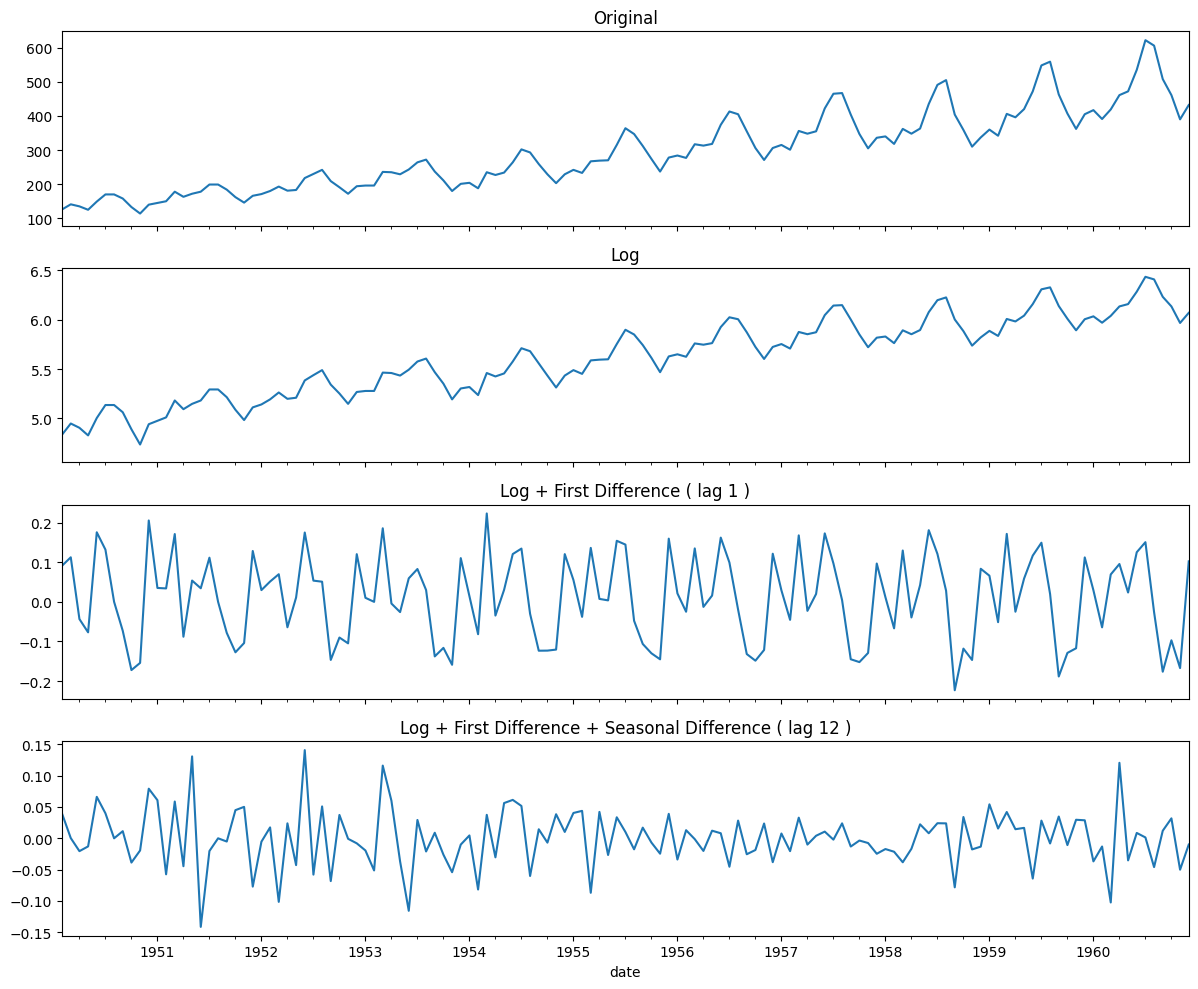

In [72]:
#Example 37 - Stationarity ( Log and Differencing )
ts_log = np.log(ts)                      # Stabilizes the variance
ts_log_diff = ts_log.diff().dropna()     # Removes the trend
ts_log_diff12 = ts_log.diff().diff(12).dropna()  # Removes the trend and the yearly seasonality

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
ts.plot(ax=axes[0], title='Original')
ts_log.plot(ax=axes[1], title='Log')
ts_log_diff.plot(ax=axes[2], title='Log + First Difference ( lag 1 )')
ts_log_diff12.plot(ax=axes[3], title='Log + First Difference + Seasonal Difference ( lag 12 )')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 04 ( Stationarity Tests - ADF and KPSS )
# ADF:  H0 = the series has a unit root ( NON-stationary ) | p-value < 0.05 suggests stationarity
# KPSS: H0 = the series IS stationary                      | p-value < 0.05 suggests NON-stationarity
# The two tests have opposite hypotheses: trust the verdict when they agree
def stationarity_report(series):
    adf_p = adfuller(series.dropna())[1]
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        kpss_p = kpss(series.dropna(), regression='c', nlags='auto')[1]
    if adf_p < 0.05 and kpss_p >= 0.05:
        verdict = 'Stationary'
    elif adf_p >= 0.05 and kpss_p < 0.05:
        verdict = 'Non-stationary'
    else:
        verdict = 'Inconclusive'
    return {'ADF p-value': round(adf_p, 4), 'KPSS p-value': round(kpss_p, 4), 'Verdict': verdict}

candidates = {
    'Original': ts,
    'Log': ts_log,
    'Log + Difference ( lag 1 )': ts_log_diff,
    'Log + Difference + Seasonal Difference ( lag 12 )': ts_log_diff12
}
pd.DataFrame({name: stationarity_report(series) for name, series in candidates.items()}).T

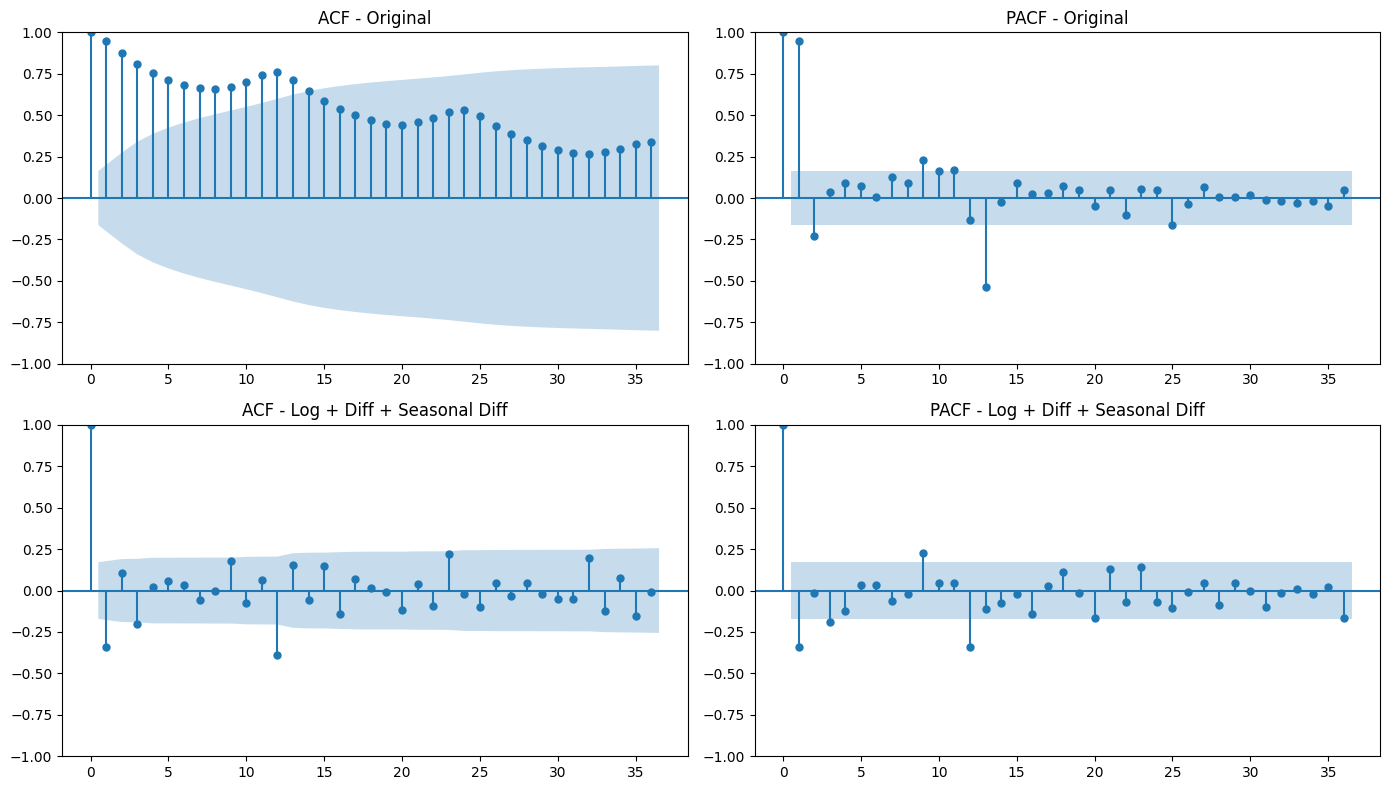

In [73]:
#Example 38 - Autocorrelation ( ACF and PACF )
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
plot_acf(ts, lags=36, ax=axes[0, 0])
axes[0, 0].set_title('ACF - Original')
plot_pacf(ts, lags=36, ax=axes[0, 1])
axes[0, 1].set_title('PACF - Original')
plot_acf(ts_log_diff12, lags=36, ax=axes[1, 0])
axes[1, 0].set_title('ACF - Log + Diff + Seasonal Diff')
plot_pacf(ts_log_diff12, lags=36, ax=axes[1, 1])
axes[1, 1].set_title('PACF - Log + Diff + Seasonal Diff')
plt.tight_layout()
plt.show()

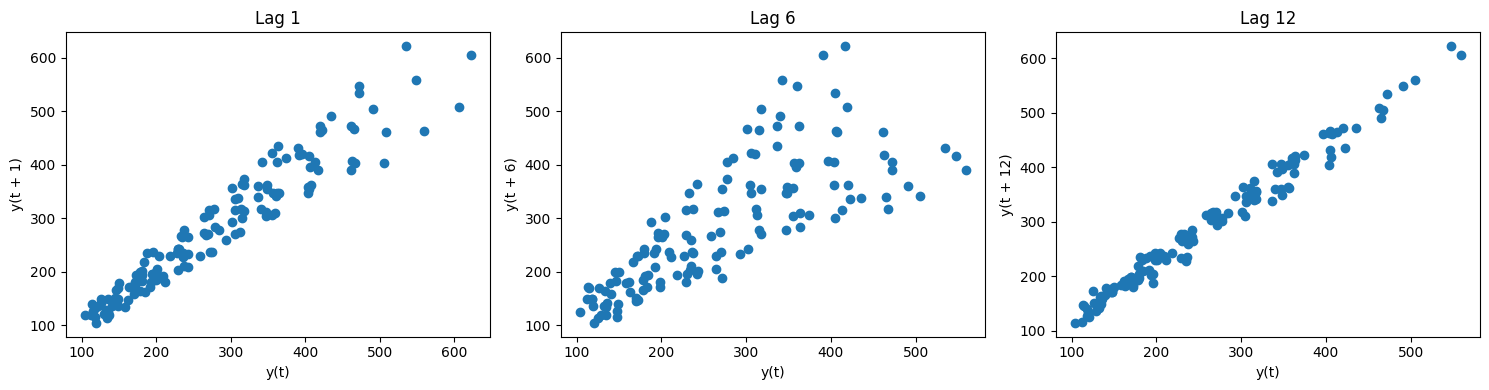

In [74]:
#Example 39 - Lag Plots ( Points on the Diagonal = Strong Autocorrelation )
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lag in zip(axes, [1, 6, 12]):
    pd.plotting.lag_plot(ts, lag=lag, ax=ax)
    ax.set_title(f'Lag {lag}')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 05 ( Ljung-Box Test - Is There Autocorrelation Left? )
# H0: the series is white noise ( no autocorrelation up to the lag ) | p-value < 0.05 = there is still structure to model
lags = [6, 12, 24]
pd.DataFrame({
    'p-value ( original )': acorr_ljungbox(ts, lags=lags, return_df=True)['lb_pvalue'],
    'p-value ( log + diff + seasonal diff )': acorr_ljungbox(ts_log_diff12, lags=lags, return_df=True)['lb_pvalue']
}).rename_axis('lag')

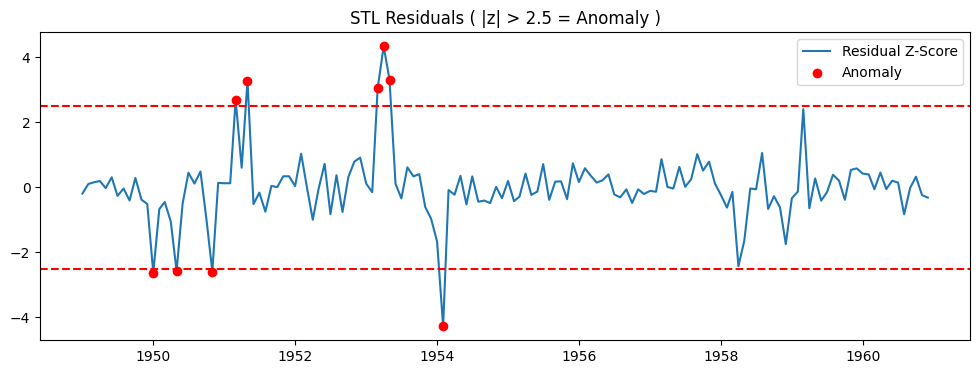

Anomalies found: 9


,resid
date,
1950-01-01,-2.63
1950-05-01,-2.58
1950-11-01,-2.59
1951-03-01,2.70
1951-05-01,3.28
1953-03-01,3.05
1953-04-01,4.35
1953-05-01,3.32
1954-02-01,-4.28


In [75]:
#Example 40 - Anomaly Detection in the Series ( STL Residual Z-Score )
stl = STL(np.log(ts), period=12, robust=True).fit()

resid = stl.resid
resid_z = (resid - resid.mean()) / resid.std()
anomalies = resid_z[resid_z.abs() > 2.5]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(resid_z, label='Residual Z-Score')
ax.axhline(2.5, color='red', linestyle='--')
ax.axhline(-2.5, color='red', linestyle='--')
ax.scatter(anomalies.index, anomalies.values, color='red', zorder=3, label='Anomaly')
ax.set_title('STL Residuals ( |z| > 2.5 = Anomaly )')
ax.legend()
plt.show()
print('Anomalies found:', len(anomalies))
anomalies.round(2)

In [ ]:
#Extra 06 ( Time-Based Train / Test Split )
# Never shuffle a time series: the test set must come AFTER the training set, exactly as it happens in production
train = ts.loc[:'1958-12-01']
test = ts.loc['1959-01-01':]
print(f'Train: {train.index.min().date()} -> {train.index.max().date()} ( {len(train)} months )')
print(f'Test : {test.index.min().date()} -> {test.index.max().date()} ( {len(test)} months )')

plt.figure(figsize=(12, 4))
plt.plot(train, label='Train')
plt.plot(test, label='Test', color='orange')
plt.axvline(test.index[0], color='gray', linestyle='--')
plt.title('Time-Based Split')
plt.legend()
plt.show()

In [ ]:
#Extra 07 ( Forecast Quality Metrics and Baselines )
# MAE and RMSE: in the unit of the series | MAPE and sMAPE: in % | MASE: error divided by the error of the seasonal naive forecast in the train set ( < 1 = better than the baseline )
def forecast_metrics(y_true, y_pred, y_train, m=12):
    y_true, y_pred, y_train = np.asarray(y_true, float), np.asarray(y_pred, float), np.asarray(y_train, float)
    error = y_true - y_pred
    scale = np.mean(np.abs(y_train[m:] - y_train[:-m]))
    return {
        'MAE': np.mean(np.abs(error)),
        'RMSE': np.sqrt(np.mean(error ** 2)),
        'MAPE_%': np.mean(np.abs(error / y_true)) * 100,
        'sMAPE_%': np.mean(2 * np.abs(error) / (np.abs(y_true) + np.abs(y_pred))) * 100,
        'MASE': np.mean(np.abs(error)) / scale
    }

baselines = {
    'Mean of the train set': pd.Series(train.mean(), index=test.index),
    'Naive ( last value )': pd.Series(train.iloc[-1], index=test.index),
    'Seasonal naive ( same month last year )': pd.Series(np.resize(train.iloc[-12:].values, len(test)), index=test.index)
}
results = pd.DataFrame({name: forecast_metrics(test, prediction, train) for name, prediction in baselines.items()}).T
results.round(2)

In [ ]:
#Extra 08 ( Holt-Winters Forecast - Trend + Multiplicative Seasonality )
# Multiplicative seasonality: the seasonal swings grow with the level of the series ( as seen in the decomposition examples )
hw_model = ExponentialSmoothing(train, trend='add', seasonal='mul', seasonal_periods=12, initialization_method='estimated').fit()
hw_forecast = hw_model.forecast(len(test))

plt.figure(figsize=(12, 4))
plt.plot(train, label='Train')
plt.plot(test, label='Test')
plt.plot(hw_forecast, label='Holt-Winters forecast', linestyle='--')
plt.title('Holt-Winters Forecast vs Real Values')
plt.legend()
plt.show()

results.loc['Holt-Winters'] = pd.Series(forecast_metrics(test, hw_forecast, train))
results.sort_values('MASE').round(2)

In [ ]:
#Extra 09 ( Walk-Forward Validation with TimeSeriesSplit )
# Each fold trains on the past and tests on the next 12 months: one test set can be lucky, five folds show how stable the model is
tscv = TimeSeriesSplit(n_splits=5, test_size=12)
rows = []

fig, ax = plt.subplots(figsize=(12, 3))
for fold, (train_idx, test_idx) in enumerate(tscv.split(ts), start=1):
    fold_train, fold_test = ts.iloc[train_idx], ts.iloc[test_idx]
    seasonal_naive = pd.Series(fold_train.iloc[-12:].values, index=fold_test.index)
    holt_winters = ExponentialSmoothing(fold_train, trend='add', seasonal='mul', seasonal_periods=12,
                                        initialization_method='estimated').fit().forecast(len(fold_test))
    rows.append({
        'fold': fold,
        'train_months': len(fold_train),
        'MAE seasonal naive': forecast_metrics(fold_test, seasonal_naive, fold_train)['MAE'],
        'MAE Holt-Winters': forecast_metrics(fold_test, holt_winters, fold_train)['MAE']
    })
    ax.barh(fold, len(train_idx), color='steelblue')
    ax.barh(fold, len(test_idx), left=len(train_idx), color='orange')
ax.set_title('TimeSeriesSplit ( Blue = Train, Orange = Test )')
ax.set_xlabel('Months')
ax.set_ylabel('Fold')
plt.tight_layout()
plt.show()

walk_forward = pd.DataFrame(rows).set_index('fold')
print(f"Mean MAE: seasonal naive = {walk_forward['MAE seasonal naive'].mean():.2f} | Holt-Winters = {walk_forward['MAE Holt-Winters'].mean():.2f}")
walk_forward.round(2)

**Findings from the examples above:** the series has 144 monthly observations ( 1949 - 1960 ) with no gaps and no duplicated timestamps; it shows a clear upward trend and a yearly seasonality whose amplitude grows with the level ( which is why the multiplicative decomposition and the log transformation are used ); and the STL residual z-score flagged 9 anomalies ( |z| > 2.5 ).
The ADF / KPSS table in *Extra 04* shows which transformation ( log, first difference, seasonal difference ) is enough to reach stationarity.

### **02. Time Series Analysis - With Random Sample**

**Attention!** From here on `df` is a small synthetic dataframe ( 50 daily observations ) created only for the examples, and it has nothing to do with the airline series `ts` above.
`attribute_1` has trend + seasonality ( 5 cycles, about 10 days each ), `attribute_2` has trend + a slower cycle ( 3 cycles ) and `attribute_3` is pure random noise.

In [76]:
#Create a Sample DataSet with the First Column
date_rng = pd.date_range(start='2025-01-01', periods=50, freq='D')
df = pd.DataFrame(date_rng, columns=['date'])
df['date'] = pd.to_datetime(df['date'])
df = df.set_index('date')

In [77]:
# Generate Random data with trend, seasonality, and randomness
np.random.seed(42)
df['attribute_1'] = np.linspace(10, 20, 50) + np.sin(np.linspace(0, 2 * np.pi, 50) * 5) * 2 + np.random.randn(50)
df['attribute_2'] = np.linspace(50, 60, 50) + np.cos(np.linspace(0, 2 * np.pi, 50) * 3) * 3 + np.random.randn(50) * 0.5
df['attribute_3'] = np.random.randn(50) * 5 + 100

In [ ]:
#Check the Frequency and the Statistics of the Sample
print('Frequency:', pd.infer_freq(df.index), '| Observations:', len(df))
df.describe().round(2)

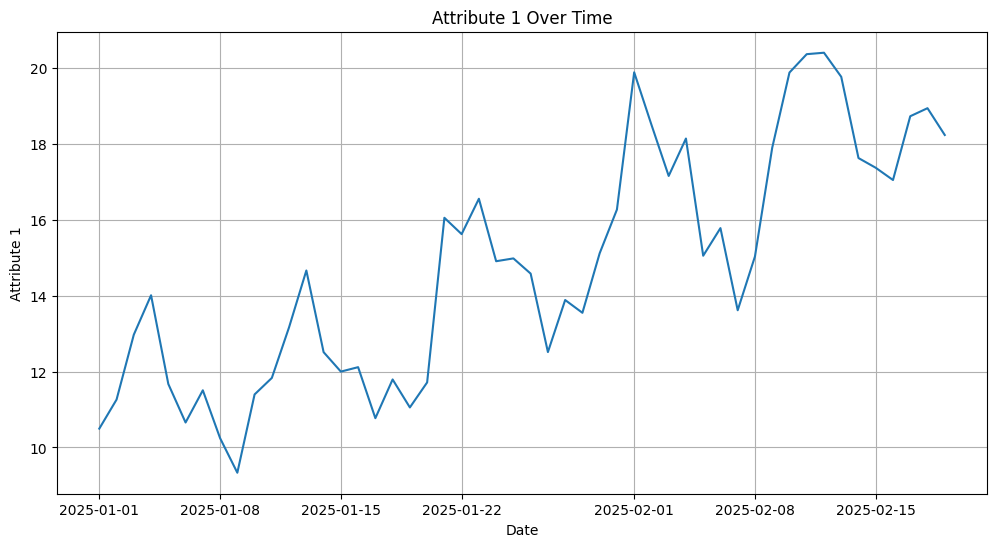

In [78]:
#Example 41
plt.figure(figsize=(12, 6))
sns.lineplot(data=df, x=df.index, y='attribute_1')
plt.title('Attribute 1 Over Time')
plt.xlabel('Date')
plt.ylabel('Attribute 1')
plt.grid(True)
plt.show()

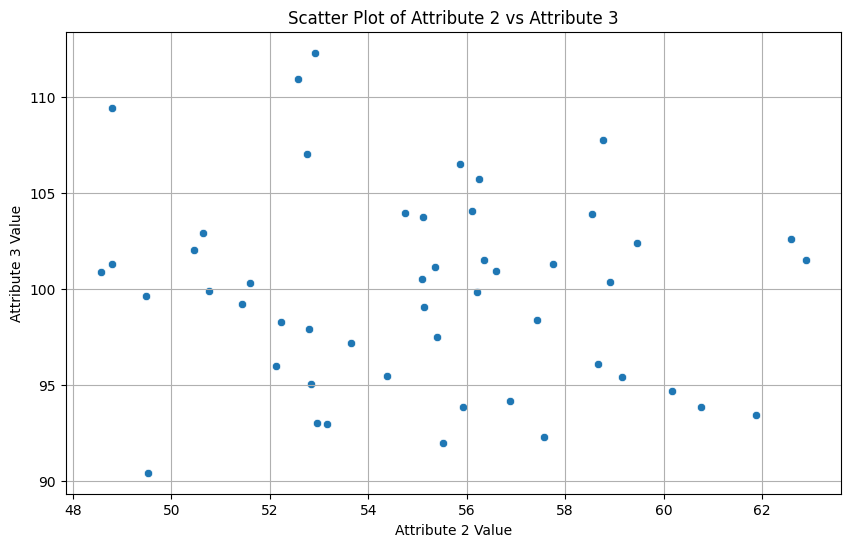

In [79]:
#Example 42
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='attribute_2', y='attribute_3')
plt.title('Scatter Plot of Attribute 2 vs Attribute 3')
plt.xlabel('Attribute 2 Value')
plt.ylabel('Attribute 3 Value')
plt.grid(True)
plt.show()

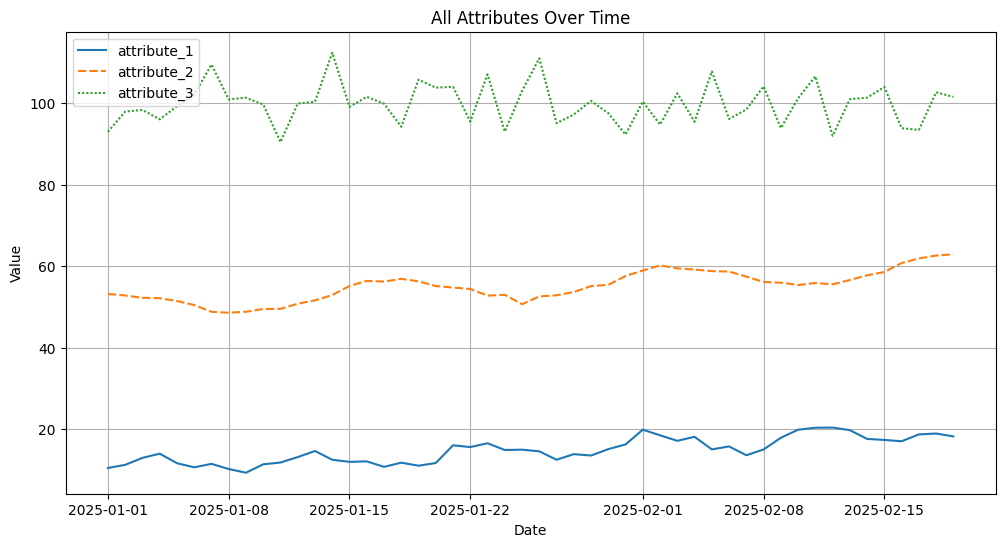

In [80]:
#Exemplo 43
plt.figure(figsize=(12, 6))
sns.lineplot(data=df)
plt.title('All Attributes Over Time')
plt.xlabel('Date')
plt.ylabel('Value')
plt.grid(True)
plt.show()

In [ ]:
#Extra 10 ( Correlation Between the Attributes )
# Attention! Two series with a trend are almost always correlated, even when they are unrelated: correlate the changes ( differences ) as well
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Correlation of the Levels')
sns.heatmap(df.diff().dropna().corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Correlation of the Daily Changes ( Differences )')
plt.tight_layout()
plt.show()

In [ ]:
#Extra 11 ( Rolling Mean to Reveal the Trend )
# A window with the same size as the seasonal cycle ( 10 days ) removes the seasonality and leaves the trend
plt.figure(figsize=(12, 4))
plt.plot(df['attribute_1'], label='Attribute 1', alpha=0.6)
plt.plot(df['attribute_1'].rolling(window=10, center=True).mean(), label='Rolling mean ( 10 days )', linewidth=2)
plt.title('Attribute 1 and Its Trend')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
#Extra 12 ( Decomposition of Attribute 1 with a 10-Day Period )
dec_attribute = seasonal_decompose(df['attribute_1'], model='additive', period=10)
dec_attribute.plot()
plt.suptitle('Additive Decomposition of Attribute 1 ( Period = 10 Days )', y=1.03)
plt.show()

In [ ]:
#Extra 13 ( Autocorrelation: Signal vs Pure Noise )
# Attribute 3 was generated as pure noise: its ACF should stay inside the confidence band and the Ljung-Box test should not reject H0
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(df['attribute_1'], lags=20, ax=axes[0])
axes[0].set_title('ACF - Attribute 1 ( Trend + Seasonality )')
plot_acf(df['attribute_3'], lags=20, ax=axes[1])
axes[1].set_title('ACF - Attribute 3 ( Noise )')
plt.tight_layout()
plt.show()

pd.DataFrame({
    'attribute_1': acorr_ljungbox(df['attribute_1'], lags=[10], return_df=True)['lb_pvalue'],
    'attribute_3': acorr_ljungbox(df['attribute_3'], lags=[10], return_df=True)['lb_pvalue']
}).rename_axis('lag')

### **Time Series Checklist**

1. **Structure:** start, end, frequency, gaps and duplicated timestamps.
2. **Look at it:** line plot, rolling statistics, resampling at different frequencies.
3. **Decompose:** trend, seasonality and residual ( additive or multiplicative ).
4. **Stationarity:** plots plus ADF and KPSS; log and differencing when needed.
5. **Autocorrelation:** ACF, PACF, lag plots and Ljung-Box.
6. **Anomalies:** residual z-score after removing trend and seasonality.
7. **Validate in time:** time-based split or walk-forward, always compared with a seasonal naive baseline.